### Imports

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from statsmodels.tsa.deterministic import CalendarFourier, DeterministicProcess

import math
from datetime import timedelta, date

### Data Processing

In [2]:
raw_ghcnd = pd.read_csv(r'../data/raw/GHCND_1980_to_2026.csv')
raw_ghcnd["DATE"] = pd.to_datetime(raw_ghcnd["DATE"])

raw_ghcnd.info()

<class 'pandas.DataFrame'>
RangeIndex: 17093 entries, 0 to 17092
Data columns (total 86 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   STATION          17093 non-null  str           
 1   NAME             17093 non-null  str           
 2   LATITUDE         17093 non-null  float64       
 3   LONGITUDE        17093 non-null  float64       
 4   ELEVATION        17093 non-null  float64       
 5   DATE             17093 non-null  datetime64[us]
 6   ACMH             5783 non-null   float64       
 7   ACMH_ATTRIBUTES  5783 non-null   str           
 8   ACSH             5783 non-null   float64       
 9   ACSH_ATTRIBUTES  5783 non-null   str           
 10  AWND             15629 non-null  float64       
 11  AWND_ATTRIBUTES  15629 non-null  str           
 12  FMTM             10180 non-null  float64       
 13  FMTM_ATTRIBUTES  10180 non-null  str           
 14  PGTM             10783 non-null  float64       
 

C:\Users\Moral\AppData\Local\Temp\ipykernel_2024\1601894922.py:1: DtypeWarning: Columns (7: ACMH_ATTRIBUTES, 9: ACSH_ATTRIBUTES, 13: FMTM_ATTRIBUTES, 19: PSUN_ATTRIBUTES, 25: TAVG_ATTRIBUTES, 31: TSUN_ATTRIBUTES, 33: WDF1_ATTRIBUTES, 39: WDFG_ATTRIBUTES, 41: WESD_ATTRIBUTES, 43: WSF1_ATTRIBUTES, 49: WSFG_ATTRIBUTES, 57: WT04_ATTRIBUTES, 59: WT05_ATTRIBUTES, 61: WT06_ATTRIBUTES, 63: WT07_ATTRIBUTES, 67: WT09_ATTRIBUTES, 69: WT10_ATTRIBUTES, 71: WT11_ATTRIBUTES, 73: WT13_ATTRIBUTES, 75: WT14_ATTRIBUTES, 77: WT15_ATTRIBUTES, 79: WT16_ATTRIBUTES, 81: WT18_ATTRIBUTES, 83: WT21_ATTRIBUTES, 85: WV03_ATTRIBUTES) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_ghcnd = pd.read_csv(r'../data/raw/GHCND_1980_to_2026.csv')


In [3]:
def persistence_ghcnd_dataset(raw_ghcnd):
    updated_df = raw_ghcnd.set_index("DATE")

    TEMP_FEATURES = [
        "TMAX", "TMIN",
        "TMAX_lag1", "TMIN_lag1"
    ]

    # Create Lag Feature
    updated_df["TMAX_lag1"] = updated_df["TMAX"].shift(1)
    updated_df["TMIN_lag1"] = updated_df["TMIN"].shift(1)

    # Split Data
    updated_df = updated_df[1:]
    train_df = updated_df[(1980 <= updated_df.index.year) & (updated_df.index.year <= 2010)][TEMP_FEATURES]
    val_df = updated_df[(2011 <= updated_df.index.year) & (updated_df.index.year <= 2017)][TEMP_FEATURES]
    test_df = updated_df[(2018 <= updated_df.index.year) & (updated_df.index.year <= 2025)][TEMP_FEATURES]

    # Interpolate Data
    train_df.interpolate(method="time", inplace=True)
    val_df.interpolate(method="time", inplace=True)
    test_df.interpolate(method="time", inplace=True)

    # Apply Shifts and Take Out First 6 Value
    return train_df, val_df, test_df

def climatological_ghcnd_dataset(raw_ghcnd):
    updated_df = raw_ghcnd.set_index("DATE")

    # Add Values Fourier Calendar Values
    TEMP_FEATURES = [
        "TMAX", "TMIN",
    ]
    
    # Split Data
    train_df = updated_df[(1980 <= updated_df.index.year) & (updated_df.index.year <= 2010)][TEMP_FEATURES]
    val_df = updated_df[(2011 <= updated_df.index.year) & (updated_df.index.year <= 2017)][TEMP_FEATURES]
    test_df = updated_df[(2018 <= updated_df.index.year) & (updated_df.index.year <= 2025)][TEMP_FEATURES]

    # Interpolate Data
    train_df.interpolate(method="time", inplace=True)
    val_df.interpolate(method="time", inplace=True)
    test_df.interpolate(method="time", inplace=True)

    # Apply Shifts and Take Out First 6 Value
    return train_df, val_df, test_df

### Baseline Models

In [4]:
persistence_train_df, persistence_val_df, persistence_test_df = persistence_ghcnd_dataset(raw_ghcnd)
climatological_train_df, climatological_val_df, climatological_test_df = climatological_ghcnd_dataset(raw_ghcnd) # For Climatology as above removes the first 6 days of 1980

print(f"Persistence:")
print(f"- Train Size: {len(persistence_train_df)}")
print(f"- Val Size: {len(persistence_val_df)}")
print(f"- Test Size: {len(persistence_test_df)}")
print(f"\nClimatological:")
print(f"- Train Size: {len(climatological_train_df)}")
print(f"- Val Size: {len(climatological_val_df)}")
print(f"- Test Size: {len(climatological_test_df)}")

Persistence:
- Train Size: 11322
- Val Size: 2557
- Test Size: 2922

Climatological:
- Train Size: 11323
- Val Size: 2557
- Test Size: 2922


#### Metrics
- Metrics to Measure: (MAE, RMSE, Mean error, Baseline_skill)

In [5]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
def mean_error(true_y:np.ndarray, pred_y:np.ndarray):
    return (pred_y - true_y).mean(axis=0)

#### Persistence

In [6]:
class PersistenceBaseline():
    def __init__(self, train_df=None):
        pass

    def predict(self, input_df):
        output_df = input_df[["TMAX_lag1", "TMIN_lag1"]].rename(columns={"TMAX_lag1": "predicted_TMAX", "TMIN_lag1": "predicted_TMIN"})
        return output_df

In [7]:
persistence_model = PersistenceBaseline()

persistence_train_output = persistence_model.predict(persistence_train_df)
persistence_train_metrics = {
    "MAE":  mean_absolute_error(persistence_train_df[["TMAX", "TMIN"]].values, persistence_train_output.values, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(persistence_train_df[["TMAX", "TMIN"]].values, persistence_train_output.values, multioutput="raw_values"),
    "ME":   mean_error(persistence_train_df[["TMAX", "TMIN"]].values, persistence_train_output.values)
}

persistence_val_output = persistence_model.predict(persistence_val_df)
persistence_val_metrics = {
    "MAE":  mean_absolute_error(persistence_val_df[["TMAX", "TMIN"]].values, persistence_val_output.values, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(persistence_val_df[["TMAX", "TMIN"]].values, persistence_val_output.values, multioutput="raw_values"),
    "ME":   mean_error(persistence_val_df[["TMAX", "TMIN"]].values, persistence_val_output.values)
}

persistence_test_output = persistence_model.predict(persistence_test_df)
persistence_test_metrics = {
    "MAE":  mean_absolute_error(persistence_test_df[["TMAX", "TMIN"]].values, persistence_test_output.values, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(persistence_test_df[["TMAX", "TMIN"]].values, persistence_test_output.values, multioutput="raw_values"),
    "ME":   mean_error(persistence_test_df[["TMAX", "TMIN"]].values, persistence_test_output.values)
}

In [8]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- MAE: {persistence_train_metrics["MAE"]}")
print(f"- RMSE: {persistence_train_metrics["RMSE"]}")
print(f"- ME: {persistence_train_metrics["ME"]}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- MAE: {persistence_val_metrics["MAE"]}")
print(f"- RMSE: {persistence_val_metrics["RMSE"]}")
print(f"- ME: {persistence_val_metrics["ME"]}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- MAE: {persistence_test_metrics["MAE"]}")
print(f"- RMSE: {persistence_test_metrics["RMSE"]}")
print(f"- ME: {persistence_test_metrics["ME"]}\n")


Train Metrics: (TMAX/TMIN)
- MAE: [3.04531002 3.46422893]
- RMSE: [4.36767405 4.93737499]
- ME: [-0.00167815 -0.00123653]

Validation Metrics: (TMAX/TMIN)
- MAE: [2.94798592 3.08486508]
- RMSE: [4.18182746 4.38345808]
- ME: [0.00312867 0.00312867]

Test Metrics: (TMAX/TMIN)
- MAE: [2.90349076 3.10198494]
- RMSE: [4.139797   4.37882846]
- ME: [0.00479124 0.00342231]



#### Climatological

In [9]:
class ClimatologicalBaseline():
    def __init__(self, train_df):
        tmp_df = train_df.copy(deep=True)
        tmp_df["DATE_OF_YEAR"] = train_df.index.strftime('%j').astype(int)
        self.climatological_model = tmp_df.groupby(by="DATE_OF_YEAR")[["TMAX", "TMIN"]].mean()

    def predict(self, input_df):
        tmp_df = input_df.copy(deep=True)
        tmp_df["DATE_OF_YEAR"] = tmp_df.index.strftime('%j').astype(int)
        return tmp_df[["DATE_OF_YEAR"]].join(self.climatological_model, on="DATE_OF_YEAR")[["TMAX", "TMIN"]].rename(columns={"TMAX": "predicted_TMAX", "TMIN": "predicted_TMIN"})

In [10]:
climatological_model = ClimatologicalBaseline(climatological_train_df)

climatological_train_output = climatological_model.predict(climatological_train_df)
climatological_train_metrics = {
    "MAE":  mean_absolute_error(climatological_train_df[["TMAX", "TMIN"]].values, climatological_train_output.values, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(climatological_train_df[["TMAX", "TMIN"]].values, climatological_train_output.values, multioutput="raw_values"),
    "ME":   mean_error(climatological_train_df[["TMAX", "TMIN"]].values, climatological_train_output.values)
}

climatological_val_output = climatological_model.predict(climatological_val_df)
climatological_val_metrics = {
    "MAE":  mean_absolute_error(climatological_val_df[["TMAX", "TMIN"]].values, climatological_val_output.values, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(climatological_val_df[["TMAX", "TMIN"]].values, climatological_val_output.values, multioutput="raw_values"),
    "ME":   mean_error(climatological_val_df[["TMAX", "TMIN"]].values, climatological_val_output.values)
}

climatological_test_output = climatological_model.predict(climatological_test_df)
climatological_test_metrics = {
    "MAE":  mean_absolute_error(climatological_test_df[["TMAX", "TMIN"]].values, climatological_test_output.values, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(climatological_test_df[["TMAX", "TMIN"]].values, climatological_test_output.values, multioutput="raw_values"),
    "ME":   mean_error(climatological_test_df[["TMAX", "TMIN"]].values, climatological_test_output.values)
}

In [11]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- MAE: {climatological_train_metrics["MAE"]}")
print(f"- RMSE: {climatological_train_metrics["RMSE"]}")
print(f"- ME: {climatological_train_metrics["ME"]}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- MAE: {climatological_val_metrics["MAE"]}")
print(f"- RMSE: {climatological_val_metrics["RMSE"]}")
print(f"- ME: {climatological_val_metrics["ME"]}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- MAE: {climatological_test_metrics["MAE"]}")
print(f"- RMSE: {climatological_test_metrics["RMSE"]}")
print(f"- ME: {climatological_test_metrics["ME"]}\n")

Train Metrics: (TMAX/TMIN)
- MAE: [3.89905787 4.75531533]
- RMSE: [5.33290177 6.46322832]
- ME: [ 1.16844527e-15 -3.36853608e-15]

Validation Metrics: (TMAX/TMIN)
- MAE: [4.05221593 5.00005677]
- RMSE: [5.33703567 6.57116074]
- ME: [-0.99674518 -2.56314103]

Test Metrics: (TMAX/TMIN)
- MAE: [4.33331125 5.49668808]
- RMSE: [5.51272404 6.93480245]
- ME: [-2.04475503 -3.57136076]



#### Comparing Climatology with Persistence

In [12]:
def baseline_skill(baseline_metrics, pred_metrics):
    return 1 - (pred_metrics['MAE']/baseline_metrics['MAE'])

In [13]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_train_metrics, persistence_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_val_metrics, persistence_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_test_metrics, persistence_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.2189626  0.27150384]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.27250029 0.38303399]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.32996026 0.43566291]



### ML Models

#### Linear Regression

In [14]:
from sklearn.linear_model import LinearRegression

In [15]:
TRAIN_MEAN = raw_ghcnd.set_index("DATE")[["TMAX", "TMIN"]][(1980 <= raw_ghcnd.set_index("DATE").index.year) & (raw_ghcnd.set_index("DATE").index.year <= 2010)].interpolate(method="time").mean()
TRAIN_STD = raw_ghcnd.set_index("DATE")[["TMAX", "TMIN"]][(1980 <= raw_ghcnd.set_index("DATE").index.year) & (raw_ghcnd.set_index("DATE").index.year <= 2010)].interpolate(method="time").std()

In [16]:
# Calculate temp deltas and ways to convert and revert them
def linear_ghcnd_dataset(raw_ghcnd):
    updated_df = raw_ghcnd.set_index("DATE")
    updated_df["DATE_OF_YEAR"] = updated_df.index.map(
        lambda x: int(x.strftime('%j'))
    )

    # Add Values Fourier Calendar Values
    updated_df["FOURIER_SIN"] = updated_df.index.map(
        lambda x: math.sin(2*math.pi*(int(x.strftime('%j')) - 1)/365)
    )

    updated_df["FOURIER_COS"] = updated_df.index.map(
        lambda x: math.cos(2*math.pi*(int(x.strftime('%j')) - 1)/365)
    )

    # Normalize Temperature
    updated_df[["TMAX", "TMIN"]] = (updated_df[["TMAX", "TMIN"]] - TRAIN_MEAN)/TRAIN_STD
    
    TEMP_FEATURES = [
        "TMAX", "TMIN",
        "TMAX_lag1", "TMIN_lag1", 
        "TMAX_lag2", "TMIN_lag2", 
        "TMAX_lag3", "TMIN_lag3", 
        "TMAX_lag4", "TMIN_lag4", 
        "TMAX_lag5", "TMIN_lag5",
        "TMAX_lag6", "TMIN_lag6",
    ]
    PRCP_FEATURES = [
        "PRCP_lag1",
        "PRCP_lag2",
        "PRCP_lag3",
        "PRCP_lag4",
        "PRCP_lag5",
        "PRCP_lag6",
    ]
    FOURIER_FEATURES = [
        "FOURIER_SIN", "FOURIER_COS",
        "FOURIER_SIN_lag1", "FOURIER_COS_lag1",
        "FOURIER_SIN_lag2", "FOURIER_COS_lag2",
        "FOURIER_SIN_lag3", "FOURIER_COS_lag3",
        "FOURIER_SIN_lag4", "FOURIER_COS_lag4",
        "FOURIER_SIN_lag5", "FOURIER_COS_lag5",
        "FOURIER_SIN_lag6", "FOURIER_COS_lag6",
    ]

    updated_df["TMAX_lag1"] = updated_df["TMAX"].shift(1)
    updated_df["TMIN_lag1"] = updated_df["TMIN"].shift(1)
    updated_df["PRCP_lag1"] = updated_df["PRCP"].shift(1)
    updated_df["FOURIER_SIN_lag1"] = updated_df["FOURIER_SIN"].shift(1)
    updated_df["FOURIER_COS_lag1"] = updated_df["FOURIER_COS"].shift(1)

    updated_df["TMAX_lag2"] = updated_df["TMAX"].shift(2)
    updated_df["TMIN_lag2"] = updated_df["TMIN"].shift(2)
    updated_df["PRCP_lag2"] = updated_df["PRCP"].shift(2)
    updated_df["FOURIER_SIN_lag2"] = updated_df["FOURIER_SIN"].shift(2)
    updated_df["FOURIER_COS_lag2"] = updated_df["FOURIER_COS"].shift(2)

    updated_df["TMAX_lag3"] = updated_df["TMAX"].shift(3)
    updated_df["TMIN_lag3"] = updated_df["TMIN"].shift(3)
    updated_df["PRCP_lag3"] = updated_df["PRCP"].shift(3)
    updated_df["FOURIER_SIN_lag3"] = updated_df["FOURIER_SIN"].shift(3)
    updated_df["FOURIER_COS_lag3"] = updated_df["FOURIER_COS"].shift(3)

    updated_df["TMAX_lag4"] = updated_df["TMAX"].shift(4)
    updated_df["TMIN_lag4"] = updated_df["TMIN"].shift(4)
    updated_df["PRCP_lag4"] = updated_df["PRCP"].shift(4)
    updated_df["FOURIER_SIN_lag4"] = updated_df["FOURIER_SIN"].shift(4)
    updated_df["FOURIER_COS_lag4"] = updated_df["FOURIER_COS"].shift(4)

    updated_df["TMAX_lag5"] = updated_df["TMAX"].shift(5)
    updated_df["TMIN_lag5"] = updated_df["TMIN"].shift(5)
    updated_df["PRCP_lag5"] = updated_df["PRCP"].shift(5)
    updated_df["FOURIER_SIN_lag5"] = updated_df["FOURIER_SIN"].shift(5)
    updated_df["FOURIER_COS_lag5"] = updated_df["FOURIER_COS"].shift(5)

    updated_df["TMAX_lag6"] = updated_df["TMAX"].shift(6)
    updated_df["TMIN_lag6"] = updated_df["TMIN"].shift(6)
    updated_df["PRCP_lag6"] = updated_df["PRCP"].shift(6)
    updated_df["FOURIER_SIN_lag6"] = updated_df["FOURIER_SIN"].shift(6)
    updated_df["FOURIER_COS_lag6"] = updated_df["FOURIER_COS"].shift(6)
    
    # Split Data
    ALL_FEATURES = TEMP_FEATURES + FOURIER_FEATURES
    updated_df = updated_df[6:]
    train_df = updated_df[(1980 <= updated_df.index.year) & (updated_df.index.year <= 2010)][ALL_FEATURES]
    val_df = updated_df[(2011 <= updated_df.index.year) & (updated_df.index.year <= 2017)][ALL_FEATURES]
    test_df = updated_df[(2018 <= updated_df.index.year) & (updated_df.index.year <= 2025)][ALL_FEATURES]

    # Interpolate Data
    train_df.interpolate(method="time", inplace=True)
    val_df.interpolate(method="time", inplace=True)
    test_df.interpolate(method="time", inplace=True)

    # Apply Shifts and Take Out First 6 Value
    return train_df, val_df, test_df

In [17]:
linear_train_df, linear_val_df, linear_test_df = linear_ghcnd_dataset(raw_ghcnd)

In [18]:
linear_train_X, linear_train_y = linear_train_df.drop(columns=["TMAX", "TMIN"]).values, linear_train_df[["TMAX", "TMIN"]].values
linear_val_X, linear_val_y = linear_val_df.drop(columns=["TMAX", "TMIN"]).values, linear_val_df[["TMAX", "TMIN"]].values
linear_test_X, linear_test_y = linear_test_df.drop(columns=["TMAX", "TMIN"]).values, linear_test_df[["TMAX", "TMIN"]].values

In [19]:
linear_model = LinearRegression()
linear_model.fit(linear_train_X, linear_train_y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2, 26)","[[ 0.74, 0.06,-0.09,...,-0.04, 9.02,-0.08], [ 0.44, 0.62,-0.17,..., 0.07, 3.74, 0.01]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](2,)","[0.,0.]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,26
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(20)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](26,)","[378.91,199.43, 97.81,..., 0. , 0. , 0. ]"


In [20]:
linear_train_normalized_output = linear_model.predict(linear_train_X)
linear_val_normalized_output = linear_model.predict(linear_val_X)
linear_test_normalized_output = linear_model.predict(linear_test_X)

linear_train_unnormalized_output = linear_train_normalized_output*TRAIN_STD.values + TRAIN_MEAN.values
linear_val_unnormalized_output = linear_val_normalized_output*TRAIN_STD.values + TRAIN_MEAN.values
linear_test_unnormalized_output = linear_test_normalized_output*TRAIN_STD.values + TRAIN_MEAN.values

linear_train_unnormalized_y = linear_train_y*TRAIN_STD.values + TRAIN_MEAN.values
linear_val_unnormalized_y = linear_val_y*TRAIN_STD.values + TRAIN_MEAN.values
linear_test_unnormalized_y = linear_test_y*TRAIN_STD.values + TRAIN_MEAN.values

In [21]:
linear_train_metrics = {
    "MAE":  mean_absolute_error(linear_train_unnormalized_output, linear_train_unnormalized_y, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(linear_train_unnormalized_output, linear_train_unnormalized_y, multioutput="raw_values"),
    "ME":   mean_error(linear_train_unnormalized_output, linear_train_unnormalized_y)
}
linear_val_metrics = {
    "MAE":  mean_absolute_error(linear_val_unnormalized_output, linear_val_unnormalized_y, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(linear_val_unnormalized_output, linear_val_unnormalized_y, multioutput="raw_values"),
    "ME":   mean_error(linear_val_unnormalized_output, linear_val_unnormalized_y)
}
linear_test_metrics = {
    "MAE":  mean_absolute_error(linear_test_unnormalized_output, linear_test_unnormalized_y, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(linear_test_unnormalized_output, linear_test_unnormalized_y, multioutput="raw_values"),
    "ME":   mean_error(linear_test_unnormalized_output, linear_test_unnormalized_y)
}

In [22]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- MAE: {linear_train_metrics["MAE"]}")
print(f"- RMSE: {linear_train_metrics["RMSE"]}")
print(f"- ME: {linear_train_metrics["ME"]}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- MAE: {linear_val_metrics["MAE"]}")
print(f"- RMSE: {linear_val_metrics["RMSE"]}")
print(f"- ME: {linear_val_metrics["ME"]}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- MAE: {linear_test_metrics["MAE"]}")
print(f"- RMSE: {linear_test_metrics["RMSE"]}")
print(f"- ME: {linear_test_metrics["ME"]}\n")

Train Metrics: (TMAX/TMIN)
- MAE: [2.80091087 2.97036059]
- RMSE: [3.93048604 4.02858223]
- ME: [-2.43607477e-16 -3.99943203e-16]

Validation Metrics: (TMAX/TMIN)
- MAE: [2.79600676 2.75649406]
- RMSE: [3.79405209 3.71589823]
- ME: [0.37850177 0.78905654]

Test Metrics: (TMAX/TMIN)
- MAE: [2.83505021 2.85860373]
- RMSE: [3.8055722  3.76435916]
- ME: [0.65776502 0.90659122]



In [23]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_train_metrics, linear_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_val_metrics, linear_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_test_metrics, linear_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.28164419 0.37535991]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.31000549 0.44870745]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.34575431 0.47994071]



In [24]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_train_metrics, linear_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_val_metrics, linear_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_test_metrics, linear_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.08025427 0.14256227]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.05155356 0.10644583]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.02357182 0.07845983]



#### XGBoost

In [25]:
import xgboost as xgb
from sklearn.model_selection import PredefinedSplit, GridSearchCV

In [26]:
def xgboost_ghcnd_dataset(raw_ghcnd):
    updated_df = raw_ghcnd.set_index("DATE")
    updated_df["DATE_OF_YEAR"] = updated_df.index.map(
        lambda x: int(x.strftime('%j'))
    )

    # Add Values Fourier Calendar Values
    updated_df["FOURIER_SIN"] = updated_df.index.map(
        lambda x: math.sin(2*math.pi*(int(x.strftime('%j')) - 1)/365)
    )

    updated_df["FOURIER_COS"] = updated_df.index.map(
        lambda x: math.cos(2*math.pi*(int(x.strftime('%j')) - 1)/365)
    )

    # Normalize Temperature
    updated_df[["TMAX", "TMIN"]] = (updated_df[["TMAX", "TMIN"]] - TRAIN_MEAN)/TRAIN_STD
    
    TEMP_FEATURES = [
        "TMAX", "TMIN",
        "TMAX_lag1", "TMIN_lag1", 
        "TMAX_lag2", "TMIN_lag2", 
        "TMAX_lag3", "TMIN_lag3", 
        "TMAX_lag4", "TMIN_lag4", 
        "TMAX_lag5", "TMIN_lag5",
        "TMAX_lag6", "TMIN_lag6",
    ]
    PRCP_FEATURES = [
        "PRCP_lag1",
        "PRCP_lag2",
        "PRCP_lag3",
        "PRCP_lag4",
        "PRCP_lag5",
        "PRCP_lag6",
    ]
    FOURIER_FEATURES = [
        "DATE_OF_YEAR",
        "FOURIER_SIN", "FOURIER_COS",
        "FOURIER_SIN_lag1", "FOURIER_COS_lag1",
        "FOURIER_SIN_lag2", "FOURIER_COS_lag2",
        "FOURIER_SIN_lag3", "FOURIER_COS_lag3",
        "FOURIER_SIN_lag4", "FOURIER_COS_lag4",
        "FOURIER_SIN_lag5", "FOURIER_COS_lag5",
        "FOURIER_SIN_lag6", "FOURIER_COS_lag6",
    ]

    updated_df["TMAX_lag1"] = updated_df["TMAX"].shift(1)
    updated_df["TMIN_lag1"] = updated_df["TMIN"].shift(1)
    updated_df["PRCP_lag1"] = updated_df["PRCP"].shift(1)
    updated_df["FOURIER_SIN_lag1"] = updated_df["FOURIER_SIN"].shift(1)
    updated_df["FOURIER_COS_lag1"] = updated_df["FOURIER_COS"].shift(1)

    updated_df["TMAX_lag2"] = updated_df["TMAX"].shift(2)
    updated_df["TMIN_lag2"] = updated_df["TMIN"].shift(2)
    updated_df["PRCP_lag2"] = updated_df["PRCP"].shift(2)
    updated_df["FOURIER_SIN_lag2"] = updated_df["FOURIER_SIN"].shift(2)
    updated_df["FOURIER_COS_lag2"] = updated_df["FOURIER_COS"].shift(2)

    updated_df["TMAX_lag3"] = updated_df["TMAX"].shift(3)
    updated_df["TMIN_lag3"] = updated_df["TMIN"].shift(3)
    updated_df["PRCP_lag3"] = updated_df["PRCP"].shift(3)
    updated_df["FOURIER_SIN_lag3"] = updated_df["FOURIER_SIN"].shift(3)
    updated_df["FOURIER_COS_lag3"] = updated_df["FOURIER_COS"].shift(3)

    updated_df["TMAX_lag4"] = updated_df["TMAX"].shift(4)
    updated_df["TMIN_lag4"] = updated_df["TMIN"].shift(4)
    updated_df["PRCP_lag4"] = updated_df["PRCP"].shift(4)
    updated_df["FOURIER_SIN_lag4"] = updated_df["FOURIER_SIN"].shift(4)
    updated_df["FOURIER_COS_lag4"] = updated_df["FOURIER_COS"].shift(4)

    updated_df["TMAX_lag5"] = updated_df["TMAX"].shift(5)
    updated_df["TMIN_lag5"] = updated_df["TMIN"].shift(5)
    updated_df["PRCP_lag5"] = updated_df["PRCP"].shift(5)
    updated_df["FOURIER_SIN_lag5"] = updated_df["FOURIER_SIN"].shift(5)
    updated_df["FOURIER_COS_lag5"] = updated_df["FOURIER_COS"].shift(5)

    updated_df["TMAX_lag6"] = updated_df["TMAX"].shift(6)
    updated_df["TMIN_lag6"] = updated_df["TMIN"].shift(6)
    updated_df["PRCP_lag6"] = updated_df["PRCP"].shift(6)
    updated_df["FOURIER_SIN_lag6"] = updated_df["FOURIER_SIN"].shift(6)
    updated_df["FOURIER_COS_lag6"] = updated_df["FOURIER_COS"].shift(6)
    
    # Split Data
    ALL_FEATURES = TEMP_FEATURES + FOURIER_FEATURES
    updated_df = updated_df[6:]
    train_df = updated_df[(1980 <= updated_df.index.year) & (updated_df.index.year <= 2010)][ALL_FEATURES]
    val_df = updated_df[(2011 <= updated_df.index.year) & (updated_df.index.year <= 2017)][ALL_FEATURES]
    test_df = updated_df[(2018 <= updated_df.index.year) & (updated_df.index.year <= 2025)][ALL_FEATURES]

    # Interpolate Data
    train_df.interpolate(method="time", inplace=True)
    val_df.interpolate(method="time", inplace=True)
    test_df.interpolate(method="time", inplace=True)

    # Apply Shifts and Take Out First 6 Value
    return train_df, val_df, test_df

In [27]:
xgboost_train_df, xgboost_val_df, xgboost_test_df = xgboost_ghcnd_dataset(raw_ghcnd)

In [28]:
xgboost_train_X, xgboost_train_y = xgboost_train_df.drop(columns=["TMAX", "TMIN"]), xgboost_train_df[["TMAX", "TMIN"]]
xgboost_val_X, xgboost_val_y = xgboost_val_df.drop(columns=["TMAX", "TMIN"]), xgboost_val_df[["TMAX", "TMIN"]]
xgboost_test_X, xgboost_test_y = xgboost_test_df.drop(columns=["TMAX", "TMIN"]), xgboost_test_df[["TMAX", "TMIN"]]

In [29]:
xgboost_train_val_X = np.concatenate((xgboost_train_X, xgboost_val_X), axis=0)
xgboost_train_val_y = np.concatenate((xgboost_train_y, xgboost_val_y), axis=0)

test_fold = [-1]*len(xgboost_train_X) + [0]*len(xgboost_val_X)
ps = PredefinedSplit(test_fold=test_fold)

In [30]:
xgboost_train_val_X = np.concatenate((xgboost_train_X, xgboost_val_X), axis=0)
xgboost_train_val_y = np.concatenate((xgboost_train_y, xgboost_val_y), axis=0)

test_fold = [-1]*len(xgboost_train_X) + [0]*len(xgboost_val_X)
ps = PredefinedSplit(test_fold=test_fold)

grid_search = GridSearchCV(
    estimator=xgb.XGBRegressor(),
    param_grid={
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.01, 0.1],
        "max_depth": [3, 6, 12],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.8, 1.0],
        "gamma": [0, 0.1]
    },
    scoring="neg_mean_squared_error",
    cv=ps,
    refit=False,
    n_jobs=-1
)

grid_search.fit(xgboost_train_val_X, xgboost_train_val_y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'gamma': [0, 0.1], 'learning_rate': [0.01, 0.1], 'max_depth': [3, 6, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",False
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.

In [31]:
xgboost_model = xgb.XGBRegressor(**grid_search.best_params_)
xgboost_model.fit(xgboost_train_X, xgboost_train_y)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,1.0
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [32]:
xgboost_train_normalized_output = xgboost_model.predict(xgboost_train_X)
xgboost_val_normalized_output = xgboost_model.predict(xgboost_val_X)
xgboost_test_normalized_output = xgboost_model.predict(xgboost_test_X)

xgboost_train_unnormalized_output = xgboost_train_normalized_output*TRAIN_STD.values + TRAIN_MEAN.values
xgboost_val_unnormalized_output = xgboost_val_normalized_output*TRAIN_STD.values + TRAIN_MEAN.values
xgboost_test_unnormalized_output = xgboost_test_normalized_output*TRAIN_STD.values + TRAIN_MEAN.values

xgboost_train_unnormalized_y = xgboost_train_y.values*TRAIN_STD.values + TRAIN_MEAN.values
xgboost_val_unnormalized_y = xgboost_val_y.values*TRAIN_STD.values + TRAIN_MEAN.values
xgboost_test_unnormalized_y = xgboost_test_y.values*TRAIN_STD.values + TRAIN_MEAN.values

In [33]:
xgboost_train_metrics = {
    "MAE":  mean_absolute_error(xgboost_train_unnormalized_output, xgboost_train_unnormalized_y, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(xgboost_train_unnormalized_output, xgboost_train_unnormalized_y, multioutput="raw_values"),
    "ME":   mean_error(xgboost_train_unnormalized_output, xgboost_train_unnormalized_y)
}
xgboost_val_metrics = {
    "MAE":  mean_absolute_error(xgboost_val_unnormalized_output, xgboost_val_unnormalized_y, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(xgboost_val_unnormalized_output, xgboost_val_unnormalized_y, multioutput="raw_values"),
    "ME":   mean_error(xgboost_val_unnormalized_output, xgboost_val_unnormalized_y)
}
xgboost_test_metrics = {
    "MAE":  mean_absolute_error(xgboost_test_unnormalized_output, xgboost_test_unnormalized_y, multioutput="raw_values"),
    "RMSE": root_mean_squared_error(xgboost_test_unnormalized_output, xgboost_test_unnormalized_y, multioutput="raw_values"),
    "ME":   mean_error(xgboost_test_unnormalized_output, xgboost_test_unnormalized_y)
}

In [34]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- MAE: {xgboost_train_metrics["MAE"]}")
print(f"- RMSE: {xgboost_train_metrics["RMSE"]}")
print(f"- ME: {xgboost_train_metrics["ME"]}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- MAE: {xgboost_val_metrics["MAE"]}")
print(f"- RMSE: {xgboost_val_metrics["RMSE"]}")
print(f"- ME: {xgboost_val_metrics["ME"]}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- MAE: {xgboost_test_metrics["MAE"]}")
print(f"- RMSE: {xgboost_test_metrics["RMSE"]}")
print(f"- ME: {xgboost_test_metrics["ME"]}\n")

Train Metrics: (TMAX/TMIN)
- MAE: [2.58383853 2.65282283]
- RMSE: [3.60227661 3.64211407]
- ME: [-3.25980063e-04 -8.49900970e-05]

Validation Metrics: (TMAX/TMIN)
- MAE: [2.75058725 2.62162501]
- RMSE: [3.75408151 3.58584631]
- ME: [0.30666544 0.77151698]

Test Metrics: (TMAX/TMIN)
- MAE: [2.75664181 2.77704795]
- RMSE: [3.73843676 3.6864642 ]
- ME: [0.59535895 0.99274325]



In [35]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_train_metrics, xgboost_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_val_metrics, xgboost_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_test_metrics, xgboost_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.33731721 0.44213524]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.32121405 0.47568095]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.36384865 0.49477796]



In [36]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_train_metrics, xgboost_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_val_metrics, xgboost_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_test_metrics, xgboost_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.15153514 0.23422416]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.06696052 0.15016542]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.05057669 0.10475131]



c:\Users\Moral\Documents\Personal Projects\WeatherForecasting\.venv\Lib\site-packages\xgboost\plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


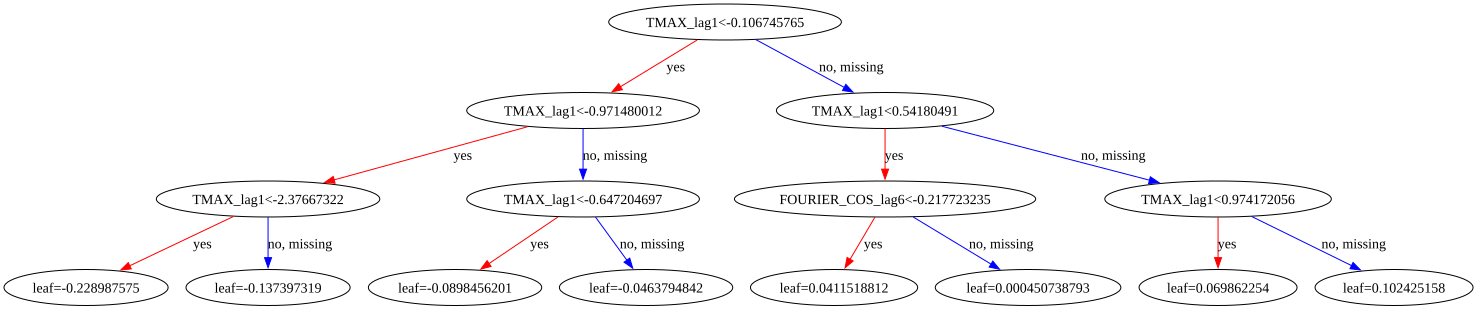

In [37]:
from IPython.display import display
graph = xgb.to_graphviz(
    xgboost_model,
    num_trees=0
)
display(graph)

In [38]:
feature_importance_dict = {x: y for x, y in zip(xgboost_train_X.columns, xgboost_model.feature_importances_)}
feature_importance_dict

{'TMAX_lag1': np.float32(0.39450625),
 'TMIN_lag1': np.float32(0.25636217),
 'TMAX_lag2': np.float32(0.004805756),
 'TMIN_lag2': np.float32(0.008302178),
 'TMAX_lag3': np.float32(0.003471135),
 'TMIN_lag3': np.float32(0.003035145),
 'TMAX_lag4': np.float32(0.00688135),
 'TMIN_lag4': np.float32(0.008245234),
 'TMAX_lag5': np.float32(0.00697728),
 'TMIN_lag5': np.float32(0.016785588),
 'TMAX_lag6': np.float32(0.012400584),
 'TMIN_lag6': np.float32(0.0051359325),
 'DATE_OF_YEAR': np.float32(0.01658943),
 'FOURIER_SIN': np.float32(0.0056075226),
 'FOURIER_COS': np.float32(0.0028369715),
 'FOURIER_SIN_lag1': np.float32(0.0023327568),
 'FOURIER_COS_lag1': np.float32(0.002401914),
 'FOURIER_SIN_lag2': np.float32(0.004200684),
 'FOURIER_COS_lag2': np.float32(0.0053856433),
 'FOURIER_SIN_lag3': np.float32(0.0030297826),
 'FOURIER_COS_lag3': np.float32(0.005935389),
 'FOURIER_SIN_lag4': np.float32(0.0062005953),
 'FOURIER_COS_lag4': np.float32(0.0110041555),
 'FOURIER_SIN_lag5': np.float32(0.004

#### RNN

In [39]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from tensordict import TensorDict

In [40]:
class RNN_GHCND_Dataset(Dataset):
    def __init__(self, ghcnd_df:pd.DataFrame):
        # Get Raw Value
        self.raw_df = ghcnd_df.copy(deep=True)
        self.raw_df.set_index("DATE", inplace=True)
        
        # Normalize Temperature
        self.raw_df[["TMAX", "TMIN"]] = (self.raw_df[["TMAX", "TMIN"]] - TRAIN_MEAN)/TRAIN_STD

        # Add Temporal Features
        self.raw_df["DATE_OF_YEAR"] = self.raw_df.index.map(
                lambda x: int(x.strftime('%j'))
            )
        
        # Add Values Fourier Calendar Values
        self.raw_df["FOURIER_SIN"] = self.raw_df.index.map(
            lambda x: math.sin(2*math.pi*(int(x.strftime('%j')) - 1)/365)
        )
    
        self.raw_df["FOURIER_COS"] = self.raw_df.index.map(
            lambda x: math.cos(2*math.pi*(int(x.strftime('%j')) - 1)/365)
        )

        self.processed_df = self.raw_df[["TMAX", "TMIN", "FOURIER_SIN", "FOURIER_COS"]]
        self.processed_df.interpolate(method="time", inplace=True)

        # Get Lag Features Plus Current Time
        self.all_lag_features = []
        self.all_current_fourier = []
        self.all_target_temps = []

        for index, curr_date in enumerate(self.processed_df.index[6:], 6):
            self.all_lag_features.append(
                [
                    self.processed_df.loc[curr_date - timedelta(days=6), ["TMAX", "TMIN", "FOURIER_SIN", "FOURIER_COS"]].values,
                    self.processed_df.loc[curr_date - timedelta(days=5), ["TMAX", "TMIN", "FOURIER_SIN", "FOURIER_COS"]].values,
                    self.processed_df.loc[curr_date - timedelta(days=4), ["TMAX", "TMIN", "FOURIER_SIN", "FOURIER_COS"]].values,
                    self.processed_df.loc[curr_date - timedelta(days=3), ["TMAX", "TMIN", "FOURIER_SIN", "FOURIER_COS"]].values,
                    self.processed_df.loc[curr_date - timedelta(days=2), ["TMAX", "TMIN", "FOURIER_SIN", "FOURIER_COS"]].values,
                    self.processed_df.loc[curr_date - timedelta(days=1), ["TMAX", "TMIN", "FOURIER_SIN", "FOURIER_COS"]].values,
                ]
            )
            self.all_current_fourier.append(
                self.processed_df.loc[curr_date, ["FOURIER_SIN", "FOURIER_COS"]].values
            )
            self.all_target_temps.append(
                self.processed_df.loc[curr_date, ["TMAX", "TMIN"]].values
            )

    def __len__(self):
        return len(self.all_lag_features)

    def __getitem__(self, idx):
        return TensorDict(
            {
                "lag_features": torch.Tensor(self.all_lag_features[idx]),
                "fourier": torch.Tensor(self.all_current_fourier[idx]),
                "target": torch.Tensor(self.all_target_temps[idx])
            },
            batch_size=[]
        )

In [41]:
rnn_train_df = raw_ghcnd[(1980 <= raw_ghcnd.DATE.map(lambda x: x.year)) & (raw_ghcnd.DATE.map(lambda x: x.year) <= 2010)]
rnn_val_df = raw_ghcnd[raw_ghcnd.DATE.between('2010-12-26', '2018-01-01', inclusive="left")] # The start at 6 days before new years day enables the collections of lag features from 6 days back
rnn_test_df = raw_ghcnd[raw_ghcnd.DATE.between('2017-12-26', '2026-01-01', inclusive="left")] # The start at 6 days before new years day enables the collections of lag features from 6 days back

In [42]:
BATCH_SIZE = 64
EPOCHS = 100

RNN_HIDDEN=32
NN_HIDDEN=64

In [43]:
rnn_train_dataset = RNN_GHCND_Dataset(rnn_train_df)
rnn_val_dataset = RNN_GHCND_Dataset(rnn_val_df)
rnn_test_dataset = RNN_GHCND_Dataset(rnn_test_df)

rnn_train_dataloader = DataLoader(rnn_train_dataset, batch_size=BATCH_SIZE)
rnn_val_dataloader = DataLoader(rnn_val_dataset, batch_size=BATCH_SIZE)
rnn_test_dataloader = DataLoader(rnn_test_dataset, batch_size=BATCH_SIZE)

C:\Users\Moral\AppData\Local\Temp\ipykernel_2024\752041517.py:5: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  self.raw_df.set_index("DATE", inplace=True)
C:\Users\Moral\AppData\Local\Temp\ipykernel_2024\752041517.py:5: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  self.raw_df.set_index("DATE", inplace=True)
C:\Users\Moral\AppData\Local\Temp\ipykernel_2024\752041517.py:5: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  self.raw_df.set_index("DATE", inplace=True)


In [44]:
class WeatherRNN(nn.Module):
    def __init__(self, RNN_HIDDEN=RNN_HIDDEN, NN_HIDDEN=NN_HIDDEN):
        super().__init__()
        self.rnn = nn.LSTM(input_size=4, hidden_size=RNN_HIDDEN, batch_first=True)
        self.fc = nn.Sequential(
            nn.Linear(RNN_HIDDEN + 2, NN_HIDDEN),
            nn.ReLU(),
            nn.Linear(NN_HIDDEN, NN_HIDDEN),
            nn.ReLU(),
            nn.Linear(NN_HIDDEN, 2)
        )

    def forward(self, x: TensorDict):
        _, (rnn_output, _) = self.rnn(x["lag_features"]) # (batch_size, 6, 4) -> (1, batch_size, RNN_HIDDEN)
        fc_input = torch.concat((rnn_output[-1], x["fourier"]), axis=-1)
        fc_output = self.fc(fc_input)
        return fc_output

In [45]:
def train_one_epoch(model, loss_fn:nn.Module, device:torch.Device, dataloader:DataLoader, optimizer:torch.optim.Optimizer):
    model.train()

    running_loss = 0
    all_predicted_temps = []
    all_true_temps = []
    for index, batch in enumerate(dataloader):
        batch = batch.to(device)
        
        optimizer.zero_grad()
        
        temp_predictions = model(batch)
        loss_value = loss_fn(temp_predictions, batch["target"])
        loss_value.backward()

        optimizer.step()
        running_loss += loss_value.item()*batch.size(0)

        all_predicted_temps.append(temp_predictions)
        all_true_temps.append(batch["target"])

    all_predicted_temps = torch.concat(all_predicted_temps, axis=0).detach().numpy()
    all_true_temps = torch.concat(all_true_temps, axis=0).detach().numpy()

    all_predicted_temps = (all_predicted_temps*TRAIN_STD.values) + TRAIN_MEAN.values
    all_true_temps = (all_true_temps*TRAIN_STD.values) + TRAIN_MEAN.values

    return {
        "MAE": mean_absolute_error(all_true_temps, all_predicted_temps, multioutput="raw_values"),
        "RMSE": root_mean_squared_error(all_true_temps, all_predicted_temps, multioutput="raw_values"),
        "ME": mean_error(all_true_temps, all_predicted_temps),
        "running_loss": running_loss/len(dataloader.dataset)
    }

def evaluate_model(model, loss_fn:nn.Module, device:torch.Device, dataloader:DataLoader):
    model.eval()
    total_loss = 0
    all_predicted_temps = []
    all_true_temps = []

    with torch.no_grad():
        for index, batch in enumerate(dataloader):
            batch = batch.to(device)

            temp_predictions = model(batch)
            loss_value = loss_fn(temp_predictions, batch["target"])

            total_loss += loss_value.item()*batch.size(0)
            all_predicted_temps.append(temp_predictions)
            all_true_temps.append(batch["target"])

    all_predicted_temps = torch.concat(all_predicted_temps, axis=0).detach().numpy()
    all_true_temps = torch.concat(all_true_temps, axis=0).detach().numpy()

    all_predicted_temps = (all_predicted_temps*TRAIN_STD.values) + TRAIN_MEAN.values
    all_true_temps = (all_true_temps*TRAIN_STD.values) + TRAIN_MEAN.values

    return {
        "MAE": mean_absolute_error(all_true_temps, all_predicted_temps, multioutput="raw_values"),
        "RMSE": root_mean_squared_error(all_true_temps, all_predicted_temps, multioutput="raw_values"),
        "ME": mean_error(all_true_temps, all_predicted_temps),
        "total_loss": total_loss/len(dataloader.dataset)
    }

In [46]:
device = torch.device(torch.accelerator.current_accelerator() if torch.accelerator.is_available() else "cpu")

rnn_model = WeatherRNN().to(device=device)

loss_fn = nn.MSELoss()
optimizer = optim.Adam(rnn_model.parameters())

In [47]:
for epoch_index in range(EPOCHS):
    rnn_interm_train_metrics = train_one_epoch(rnn_model, loss_fn, device, rnn_train_dataloader, optimizer)
    if (epoch_index % 10 == 0 or epoch_index == EPOCHS - 1):
        print(f"Epoch {epoch_index + 1}:")
        print(f"- Train:")
        print(f"\t- MAE: {rnn_interm_train_metrics["MAE"]}")
        print(f"\t- RMSE: {rnn_interm_train_metrics["RMSE"]}")
        print(f"\t- ME: {rnn_interm_train_metrics["ME"]}")
        print(f"\t- running_loss: {rnn_interm_train_metrics["running_loss"]}")

        rnn_interm_val_metrics = evaluate_model(rnn_model, loss_fn, device, rnn_val_dataloader)

        print(f"- Validation:")
        print(f"\t- MAE: {rnn_interm_val_metrics["MAE"]}")
        print(f"\t- RMSE: {rnn_interm_val_metrics["RMSE"]}")
        print(f"\t- ME: {rnn_interm_val_metrics["ME"]}")
        print(f"\t- total_loss: {rnn_interm_val_metrics["total_loss"]}")

rnn_train_metrics = evaluate_model(rnn_model, loss_fn, device, rnn_train_dataloader)
rnn_val_metrics = evaluate_model(rnn_model, loss_fn, device, rnn_val_dataloader)
rnn_test_metrics = evaluate_model(rnn_model, loss_fn, device, rnn_test_dataloader)

C:\Users\Moral\AppData\Local\Temp\ipykernel_2024\752041517.py:56: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:252.)
  "lag_features": torch.Tensor(self.all_lag_features[idx]),
C:\Users\Moral\AppData\Local\Temp\ipykernel_2024\752041517.py:57: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  "fourier": torch.Tensor(self.all_current_fourier[idx]),


Epoch 1:
- Train:
	- MAE: [4.42868196 5.15867953]
	- RMSE: [6.06680424 7.07426001]
	- ME: [-0.08972707 -0.07457116]
	- running_loss: 0.4167506636147618
- Validation:
	- MAE: [3.51651863 3.50486843]
	- RMSE: [4.54984881 4.77062931]
	- ME: [-1.04887463 -1.57330797]
	- total_loss: 0.212675566464884
Epoch 11:
- Train:
	- MAE: [2.79263593 2.85608325]
	- RMSE: [3.91814582 3.92717297]
	- ME: [0.00012873 0.00036826]
	- running_loss: 0.1518533023895071
- Validation:
	- MAE: [2.95482223 2.66900784]
	- RMSE: [3.97225216 3.6945794 ]
	- ME: [-0.85496928 -0.35207398]
	- total_loss: 0.14720127816353173
Epoch 21:
- Train:
	- MAE: [2.74979101 2.78727548]
	- RMSE: [3.86159958 3.83721448]
	- ME: [0.00076401 0.00083488]
	- running_loss: 0.1464678037289839
- Validation:
	- MAE: [2.88057168 2.64747672]
	- RMSE: [3.91230447 3.66127081]
	- ME: [-0.69104159 -0.36352389]
	- total_loss: 0.1434523884526071
Epoch 31:
- Train:
	- MAE: [2.72799945 2.77010633]
	- RMSE: [3.82562594 3.81101333]
	- ME: [-0.00029216  0.0

In [48]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- MAE: {rnn_train_metrics["MAE"]}")
print(f"- RMSE: {rnn_train_metrics["RMSE"]}")
print(f"- ME: {rnn_train_metrics["ME"]}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- MAE: {rnn_val_metrics["MAE"]}")
print(f"- RMSE: {rnn_val_metrics["RMSE"]}")
print(f"- ME: {rnn_val_metrics["ME"]}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- MAE: {rnn_test_metrics["MAE"]}")
print(f"- RMSE: {rnn_test_metrics["RMSE"]}")
print(f"- ME: {rnn_test_metrics["ME"]}\n")

Train Metrics: (TMAX/TMIN)
- MAE: [2.55589163 2.68959313]
- RMSE: [3.5410124  3.64879935]
- ME: [-0.20209961  0.5627576 ]

Validation Metrics: (TMAX/TMIN)
- MAE: [2.83765377 2.58366031]
- RMSE: [3.92922349 3.62891835]
- ME: [-0.47447689 -0.22109811]

Test Metrics: (TMAX/TMIN)
- MAE: [2.85524452 2.64402083]
- RMSE: [3.93007223 3.64675925]
- ME: [-0.72687607 -0.43339795]



In [49]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_train_metrics, xgboost_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_val_metrics, xgboost_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(climatological_test_metrics, xgboost_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.33731721 0.44213524]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.32121405 0.47568095]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.36384865 0.49477796]



In [50]:
print("Train Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_train_metrics, xgboost_train_metrics)}\n")

print("Validation Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_val_metrics, xgboost_val_metrics)}\n")

print("Test Metrics: (TMAX/TMIN)")
print(f"- Baseline: {baseline_skill(persistence_test_metrics, xgboost_test_metrics)}\n")

Train Metrics: (TMAX/TMIN)
- Baseline: [0.15153514 0.23422416]

Validation Metrics: (TMAX/TMIN)
- Baseline: [0.06696052 0.15016542]

Test Metrics: (TMAX/TMIN)
- Baseline: [0.05057669 0.10475131]

